# Portfolio risk analysis

Runs the full pipeline (parse → holdings → time-weighted returns → metrics → charts).

* By default it uses the **synthetic sample data** in `data_sample/`, so anyone can run it.
* Set `USE_PRIVATE_DATA = True` to run on real exports in `data_private/` (local only).
  Outputs then go to `data_private/output/`. **Clear all outputs before committing** this
  notebook after a private run, and run `python check_public_outputs.py`.

All methods and formulas are documented in the README and in the docstrings of `src/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from IPython.display import Image, Markdown, display
from src import pipeline

USE_PRIVATE_DATA = False   # True = real data in data_private/ (never commit the outputs)

In [2]:
results = pipeline.run(private=USE_PRIVATE_DATA)
start, end = results["period"]
print(f"Period analysed: {start} to {end}")

Period analysed: 2024-02-07 to 2026-10-22


## Headline metrics

Returns are time-weighted (deposits and withdrawals do not affect them), in EUR, pre-tax.
Annualised return is left blank for periods shorter than one year.

In [3]:
pipeline.format_summary(results["summary"]).T

,Portfolio,Benchmark (from 2024-02-07),Index ETF sleeve,Individual stock sleeve,Benchmark (from 2024-03-12)
total_return,45.90%,49.82%,43.58%,87.19%,47.12%
annualised_return,14.96%,16.10%,14.29%,27.07%,15.90%
volatility,11.79%,13.48%,12.51%,25.80%,13.61%
max_drawdown,-18.62%,-21.59%,-18.86%,-33.20%,-21.59%
max_drawdown_peak,2025-02-18,2025-02-19,2025-02-18,2024-12-26,2025-02-19
max_drawdown_trough,2025-04-07,2025-04-09,2025-04-09,2025-04-08,2025-04-09
max_drawdown_recovery,2025-09-12,2025-10-03,2025-10-01,2025-09-22,2025-10-03
sharpe,1.02,0.98,0.92,0.96,0.96
beta,0.82,1.00,0.89,0.58,1.00
alpha_annual,1.12%,0.00%,-0.28%,17.07%,-0.00%


## Where the gap to the benchmark comes from

Each day the excess return over the benchmark is split exactly into sleeve, cash and cost
contributions; the sums over the period are shown in percentage points. The compounding
line reconciles the sum of daily contributions with the gap between the cumulative returns.

In [4]:
(results["attribution"] * 100).round(2).to_frame("percentage points")

,percentage points
Index ETF sleeve,-4.19
Individual stock sleeve,2.36
"Cash (interest, FX, cash drag)",-1.29
"Costs (commissions, fees)",-0.12
Compounding effect,-0.69
Total gap to benchmark,-3.92


## Charts

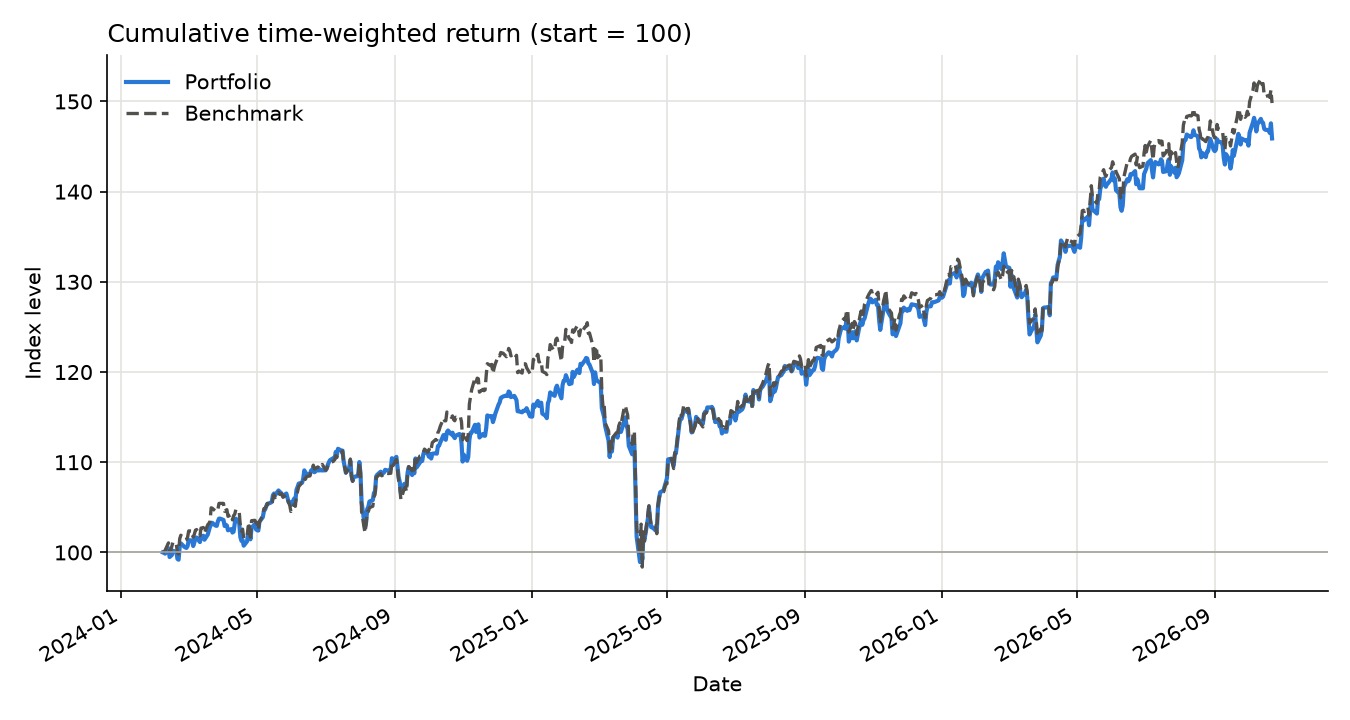

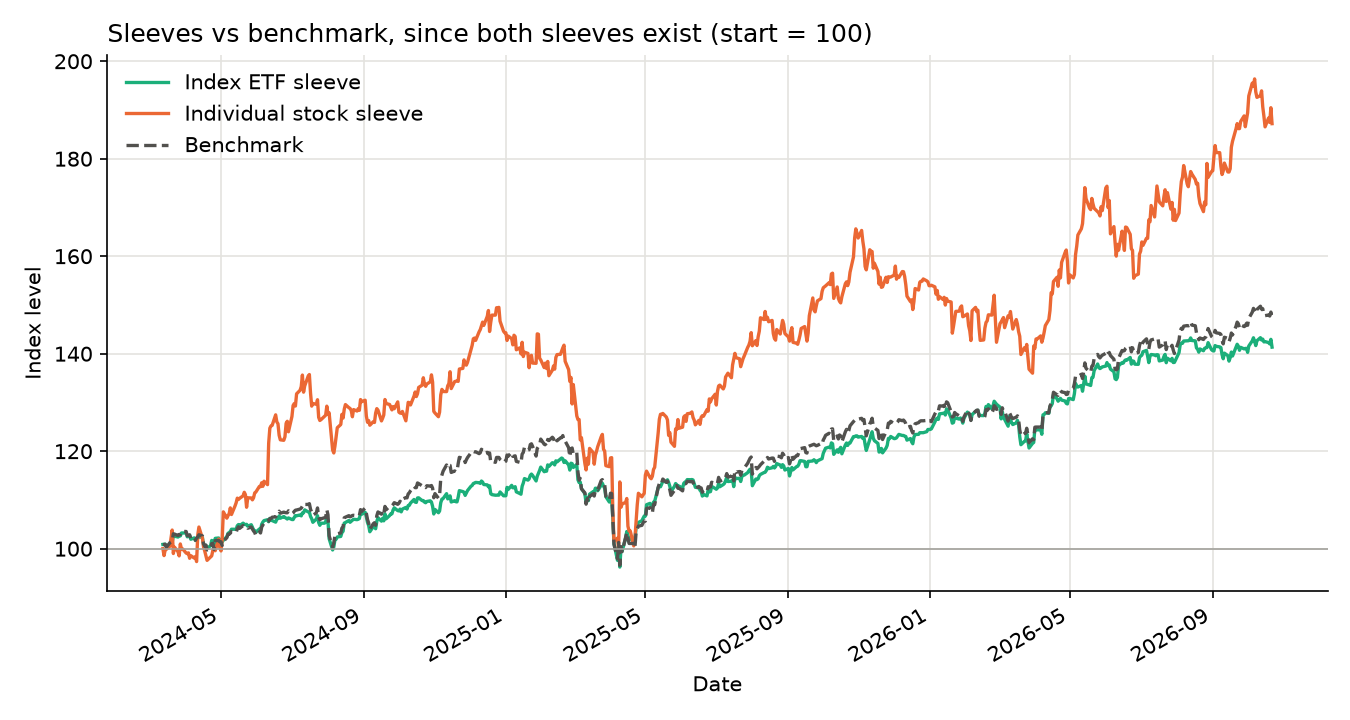

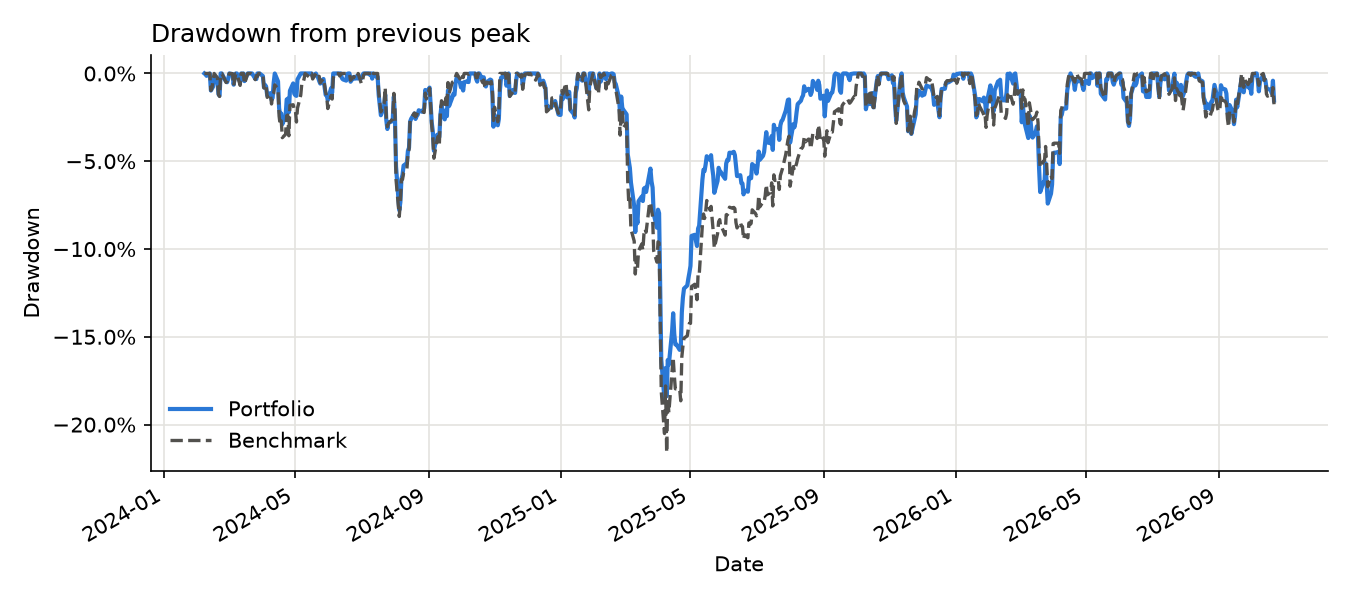

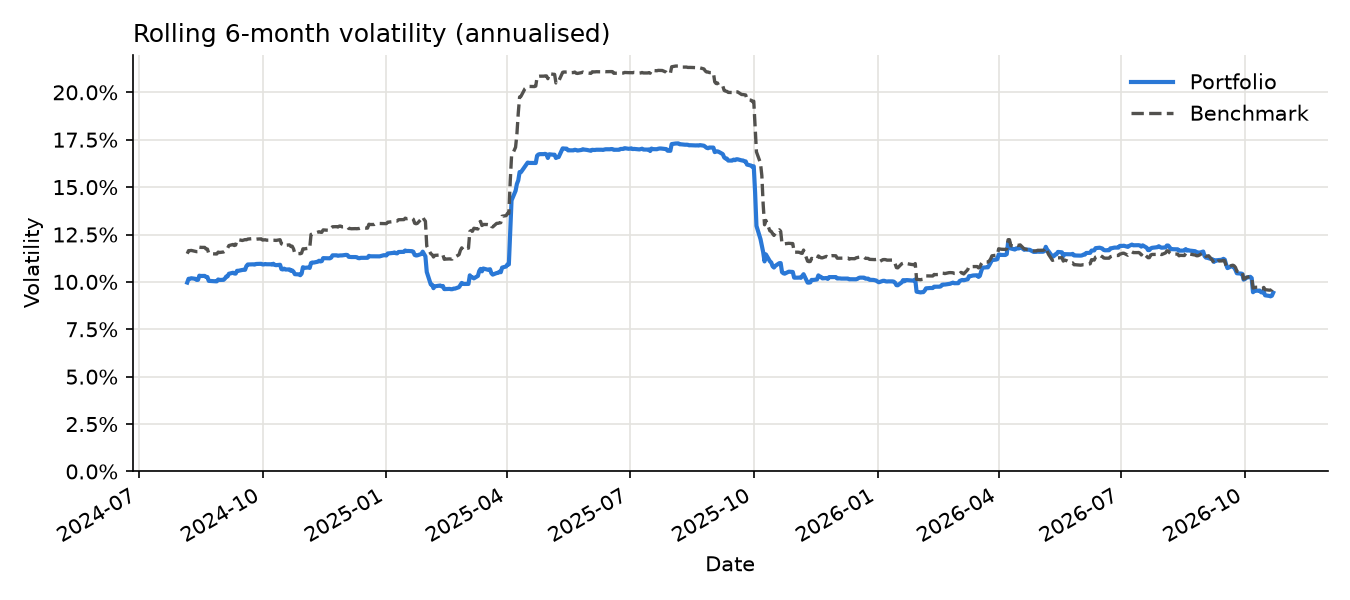

In [5]:
out = Path(results["out_dir"])
for name in ["cumulative_return", "sleeves_vs_benchmark", "drawdown", "rolling_volatility"]:
    path = out / f"{name}.png"
    if path.exists():
        display(Image(filename=str(path)))

## Data quality notes

Anything estimated or missing is listed here (empty list = nothing flagged).

In [6]:
results["notes"]

[]